# **Machine Learning Project**

## **Code Section**

## **Import Libraries**

In [ ]:
import scipy.io as sio
import os
import cv2
import numpy as np
import pandas as pd
import re
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from scipy.ndimage import gaussian_filter

## **1. Download Mall Dataset**

In [ ]:
!wget http://personal.ie.cuhk.edu.hk/~ccloy/files/datasets/mall_dataset.zip
!unzip mall_dataset.zip -d mall_dataset

--2025-12-06 18:59:34--  http://personal.ie.cuhk.edu.hk/~ccloy/files/datasets/mall_dataset.zip
Resolving personal.ie.cuhk.edu.hk (personal.ie.cuhk.edu.hk)... 137.189.99.12
Connecting to personal.ie.cuhk.edu.hk (personal.ie.cuhk.edu.hk)|137.189.99.12|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 91833998 (88M) [application/zip]
Saving to: ‘mall_dataset.zip’

mall_dataset.zip    100%[===================>]  87.58M  6.22MB/s    in 19s     

2025-12-06 18:59:54 (4.58 MB/s) - ‘mall_dataset.zip’ saved [91833998/91833998]

Archive:  mall_dataset.zip
   creating: mall_dataset/mall_dataset/
  inflating: mall_dataset/mall_dataset/demo.m  
   creating: mall_dataset/mall_dataset/frames/
  inflating: mall_dataset/mall_dataset/frames/seq_000001.jpg  
  inflating: mall_dataset/mall_dataset/frames/seq_000002.jpg  
  inflating: mall_dataset/mall_dataset/frames/seq_000003.jpg  
  inflating: mall_dataset/mall_dataset/frames/seq_000004.jpg  
  inflating: mall_dataset/mall_dataset

## **2. Load Ground Truth (.mat file)**

In [ ]:
gt = sio.loadmat("mall_dataset/mall_dataset/mall_gt.mat")
counts = gt["count"]

print("Number of labels:", len(counts))  # 2000 crowd count labels

Number of labels: 2000


## **3. Load Images + Match Them with Ground Truth**

In [ ]:
image_folder = "mall_dataset/mall_dataset/frames/"
files = os.listdir(image_folder)

# Filter images: Official mall dataset format "seq_000001.jpg"
pattern = re.compile(r"seq_\d{6}\.jpg")

valid_files = sorted([f for f in files if pattern.match(f)])

print("Number of valid images found:", len(valid_files))

images = []
labels = []

# Read all 2000 images and match with correct GT value
for i, filename in enumerate(valid_files):
    img_path = os.path.join(image_folder, filename)
    img = cv2.imread(img_path)

    img = cv2.resize(img, (128, 128))
    img = img / 255.0

    images.append(img)
    labels.append(counts[i][0])

images = np.array(images)
labels = np.array(labels)

print("Images:", images.shape)
print("Labels:", labels.shape)

Number of valid images found: 2000
Images: (2000, 128, 128, 3)
Labels: (2000,)


## **4. Train/Test Split**

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    images, labels, test_size=0.2, random_state=42
)

print("Train:", x_train.shape, y_train.shape)
print("Test:", x_test.shape, y_test.shape)

Train: (1600, 128, 128, 3) (1600,)
Test: (400, 128, 128, 3) (400,)


## **5. Build CNN Model**

In [ ]:
model = models.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(128,128,3)),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),

    layers.Flatten(),
    layers.Dense(64, activation='relu'),
    layers.Dense(1)  # Output = predicted crowd count
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,605,696 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,699,009 (6.48 MB)

 Trainable params: 1,699,009 (6.48 MB)

 Non-trainable params: 0 (0.00 B)

## **6. Train the Model (Basic Training)**

In [ ]:
history = model.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    epochs=20,
    batch_size=16
)

Epoch 1/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 49s 485ms/step - loss: 2.4474 - mae: 1.2702 - val_loss: 6.0170 - val_mae: 1.9616
Epoch 2/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 48s 482ms/step - loss: 1.9792 - mae: 1.1284 - val_loss: 6.5061 - val_mae: 1.9865
Epoch 3/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 45s 454ms/step - loss: 1.6668 - mae: 1.0301 - val_loss: 6.0723 - val_mae: 1.9318
Epoch 4/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 46s 464ms/step - loss: 2.5582 - mae: 1.2938 - val_loss: 5.9025 - val_mae: 1.8764
Epoch 5/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 81s 452ms/step - loss: 1.6627 - mae: 1.0332 - val_loss: 6.7696 - val_mae: 2.0048
Epoch 6/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 84s 478ms/step - loss: 1.7005 - mae: 1.0528 - val_loss: 6.3222 - val_mae: 1.9844
Epoch 7/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 81s 467ms/step - loss: 1.2831 - mae: 0.9070 - val_loss: 6.1461 - val_mae: 1.9350
Epoch 8/20
100/100 ━━━━━━━━━━━━━━━━━━━━ 82s 472ms/step - loss: 1.0255 - mae: 0.8100 - val_loss: 5.8887 - val_mae: 1.9142
Epoch 9/20
100/100 ━━━━━━━━━━━━━

## **7. Evaluate the Model on Test Set**

In [ ]:
loss, mae = model.evaluate(x_test, y_test)
print("Test MAE:", mae)

13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 318ms/step - loss: 6.4499 - mae: 1.9901
Test MAE: 1.8925070762634277


## **8. Improved Training (EarlyStopping + Checkpoint)**

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=8,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    'best_model.keras',
    monitor='val_loss',
    save_best_only=True
)

history = model.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    epochs=50,
    batch_size=16,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 49s 491ms/step - loss: 1.5453 - mae: 1.0118 - val_loss: 6.4565 - val_mae: 2.0080
Epoch 2/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 46s 462ms/step - loss: 0.5256 - mae: 0.5641 - val_loss: 6.6867 - val_mae: 2.0269
Epoch 3/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 45s 450ms/step - loss: 0.5416 - mae: 0.5815 - val_loss: 6.4040 - val_mae: 1.9980
Epoch 4/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 83s 462ms/step - loss: 0.2394 - mae: 0.3919 - val_loss: 6.6739 - val_mae: 2.0093
Epoch 5/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 46s 458ms/step - loss: 0.1977 - mae: 0.3573 - val_loss: 6.3480 - val_mae: 1.9550
Epoch 6/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 85s 486ms/step - loss: 0.1449 - mae: 0.3040 - val_loss: 6.4209 - val_mae: 1.9810
Epoch 7/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 79s 462ms/step - loss: 0.1138 - mae: 0.2642 - val_loss: 6.8902 - val_mae: 2.0202
Epoch 8/50
100/100 ━━━━━━━━━━━━━━━━━━━━ 83s 476ms/step - loss: 0.1056 - mae: 0.2568 - val_loss: 6.4132 - val_mae: 1.9820
Epoch 9/50
100/100 ━━━━━━━━━━━━━

## **9. Plot Training Curves**

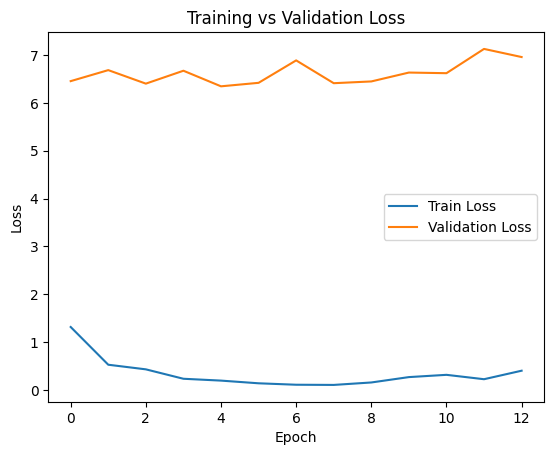

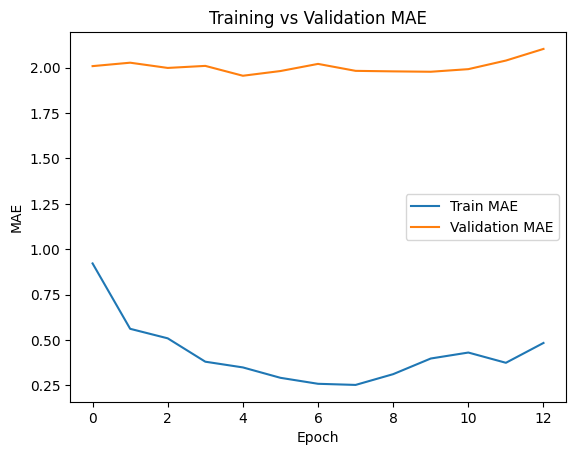

In [ ]:
# Loss curve
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

# MAE curve
plt.plot(history.history['mae'], label='Train MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')
plt.title("Training vs Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()
plt.show()

## **10. Model Inference (Predict on One Image)**

In [ ]:
def predict_count(image_path):
    img = cv2.imread(image_path)
    img_resized = cv2.resize(img, (128, 128)) / 255.0
    img_resized = np.expand_dims(img_resized, axis=0)

    prediction = model.predict(img_resized)
    return int(prediction[0][0])

## **11. Evaluate Model (MAE, RMSE, MAPE)**

In [ ]:
# === MODEL PERFORMANCE EVALUATION ===

# Predict all test data
y_pred = model.predict(x_test).flatten()

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
mape = np.mean(np.abs((y_test - y_pred) / (y_test + 1e-5))) * 100

print("\n📊 MODEL PERFORMANCE METRICS")
print("------------------------------------")
print(f"MAE  (Mean Absolute Error): {mae:.2f}")
print(f"RMSE (Root Mean Squared Error): {rmse:.2f}")
print(f"MAPE (Mean Absolute Percentage Error): {mape:.2f}%")
print("------------------------------------\n")

13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 321ms/step

📊 MODEL PERFORMANCE METRICS
------------------------------------
MAE  (Mean Absolute Error): 1.96
RMSE (Root Mean Squared Error): 2.52
MAPE (Mean Absolute Percentage Error): 6.26%
------------------------------------



## **12. Define Safety Threshold**

In [ ]:
# === SAFETY THRESHOLD FOR HAJJ/UMRAH ===
high_density_threshold = 40  # You can change this value
num_examples = 5  # Number of images to display as examples

print(f"High-density threshold set to: {high_density_threshold}")


High-density threshold set to: 40


## **13. Function to Display Image + GT + Prediction + Alert**

In [ ]:
# === FUNCTION TO DISPLAY SAMPLE PREDICTIONS ===

def show_prediction(idx):
    """Displays image, GT, model prediction, and safety alert."""
    img = x_test[idx]
    true_count = int(y_test[idx])
    predicted = float(model.predict(img.reshape(1, 128, 128, 3))[0])

    # Show image and predictions
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(f"GT: {true_count} | Prediction: {predicted:.1f}", fontsize=14)
    plt.show()

    # Safety alert
    if predicted > high_density_threshold:
        print("⚠️ High Crowd Warning:")
        print("   Predicted high-density crowd detected.")
        print("   Recommend crowd flow redirection or safety intervention.\n")
    else:
        print("✔️ Normal Density: No safety actions required.\n")

## **14. Show Multiple Images (5 Examples)**

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step


/tmp/ipython-input-4114796231.py:7: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  predicted = float(model.predict(img.reshape(1, 128, 128, 3))[0])


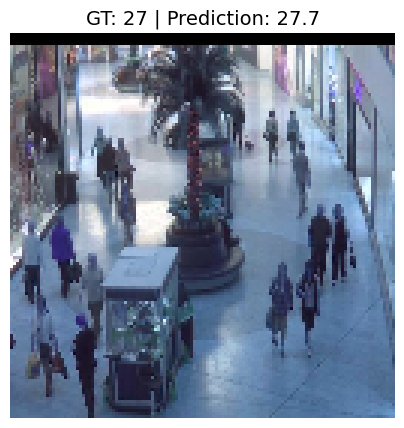

✔️ Normal Density: No safety actions required.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


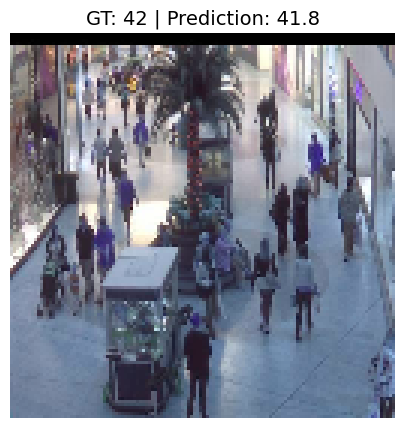

⚠️ High Crowd Warning:
   Predicted high-density crowd detected.
   Recommend crowd flow redirection or safety intervention.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


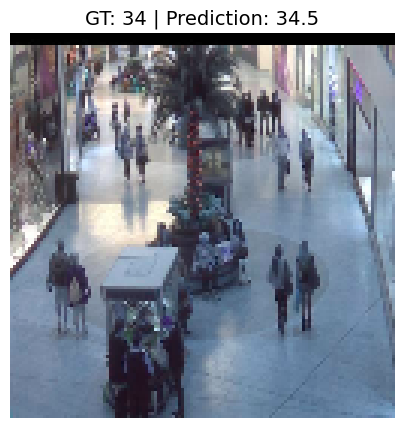

✔️ Normal Density: No safety actions required.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


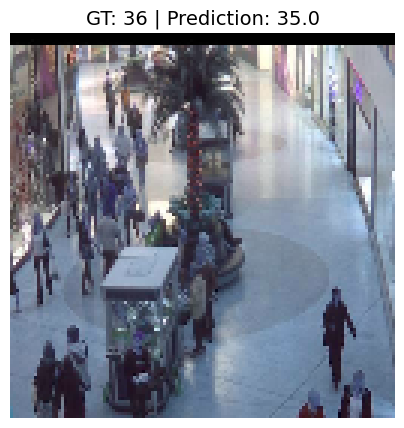

✔️ Normal Density: No safety actions required.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step


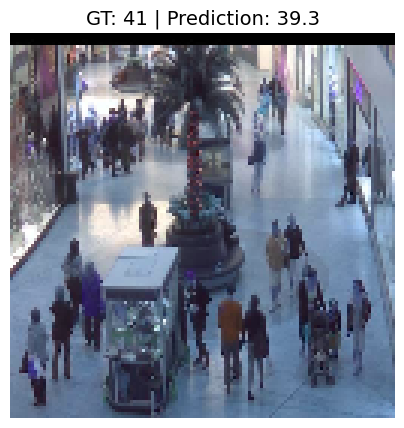

✔️ Normal Density: No safety actions required.



In [ ]:
# === DISPLAY MULTIPLE RANDOM EXAMPLES ===

indices = np.random.choice(len(x_test), num_examples, replace=False)

for idx in indices:
    show_prediction(idx)

## **15. Generate Density Maps**

In [ ]:
def generate_density_map(img, predicted_count):
    """
    Generates a simple density heatmap based on predicted count.
    This is not true crowd localization, but it visualizes density intensity.
    """
    h, w, _ = img.shape
    heatmap = np.zeros((h, w))

    # Random distribution of points to simulate crowd density
    # (Since dataset does not include person locations)
    pts = np.random.randint(0, h, (int(predicted_count), 2))

    for p in pts:
        heatmap[p[0] % h, p[1] % w] += 1

    # Apply Gaussian filter for smooth heatmap
    heatmap = gaussian_filter(heatmap, sigma=8)
    return heatmap

## **16. Heatmap Overlay on Image**

In [ ]:
def overlay_heatmap(img, density_map):
    density_norm = density_map / (density_map.max() + 1e-9)
    heat = cv2.applyColorMap((density_norm * 255).astype(np.uint8), cv2.COLORMAP_JET)
    heat = cv2.cvtColor(heat, cv2.COLOR_BGR2RGB)

    overlay = (0.6 * img + 0.4 * heat).astype(np.uint8)
    return overlay

## **17. Function to Display Everything + Alerts**

In [ ]:
# === Display Full Visualization for One Sample ===

def show_full_visualization(idx):
    img = x_test[idx]
    gt = int(y_test[idx])
    pred = float(model.predict(img.reshape(1, 128, 128, 3))[0])

    # Generate density map and heatmap overlay
    density = generate_density_map(img, pred)
    overlay = overlay_heatmap(img, density)

    # Display results
    plt.figure(figsize=(15, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(img)
    plt.title(f"Original Image\nGT: {gt} | Prediction: {pred:.1f}")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(density, cmap="jet")
    plt.title("Density Heatmap")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(overlay)
    plt.title("Overlay on Image")
    plt.axis("off")

    plt.show()

    # Safety alert for Hajj/Umrah application
    if pred > high_density_threshold:
        print("⚠️ High Crowd Warning: Unsafe density detected!\n")
    else:
        print("✔️ Density Normal.\n")

## **18. Show Multiple Samples**

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


/tmp/ipython-input-1242924405.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  pred = float(model.predict(img.reshape(1, 128, 128, 3))[0])


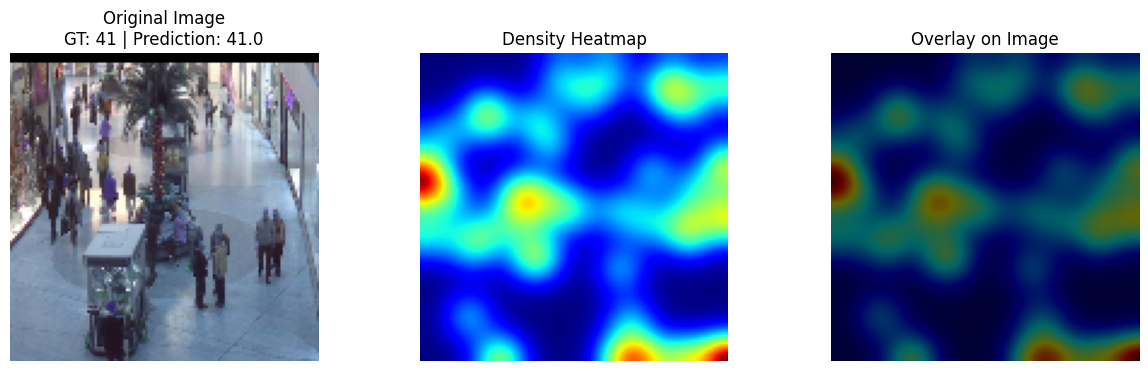

⚠️ High Crowd Warning: Unsafe density detected!

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step


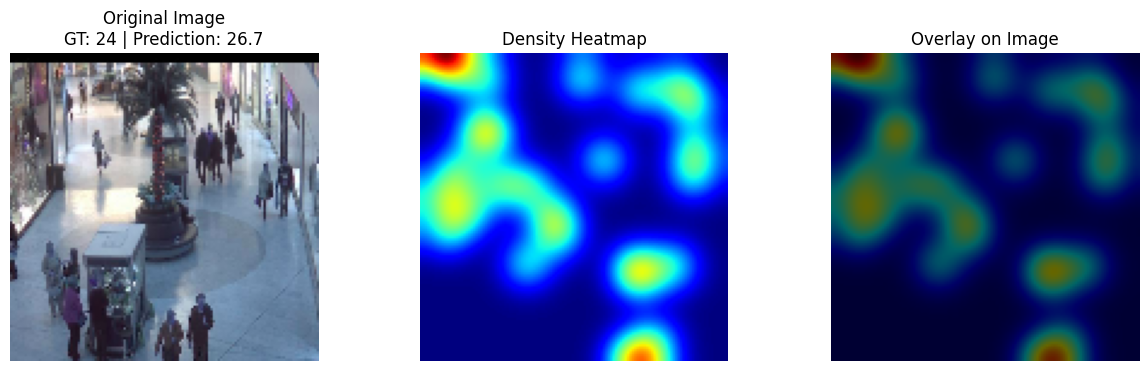

✔️ Density Normal.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step


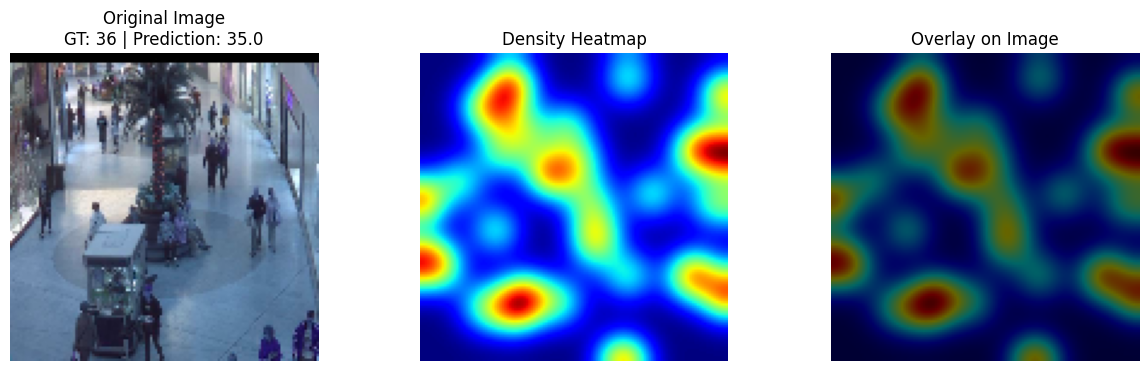

✔️ Density Normal.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 62ms/step


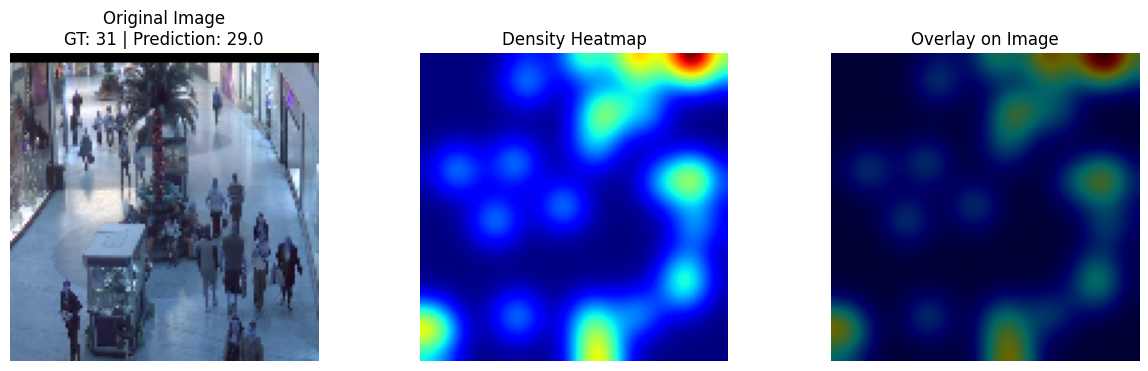

✔️ Density Normal.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step


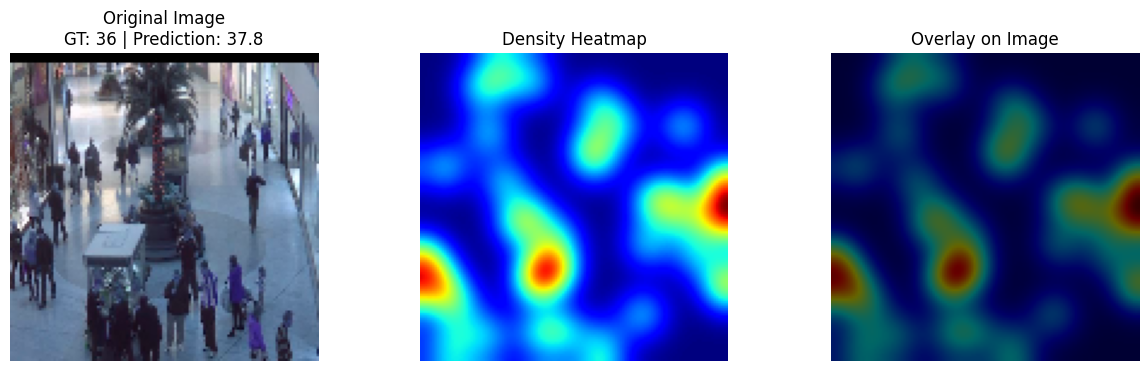

✔️ Density Normal.



In [ ]:
# === Show 5 Random Examples with Full Visualization ===

indices = np.random.choice(len(x_test), 5, replace=False)

for idx in indices:
    show_full_visualization(idx)

## **19. Save Outputs Automatically**

In [ ]:
# === Save All Visual Outputs Automatically ===

os.makedirs("results", exist_ok=True)

def save_output(idx):
    img = x_test[idx]
    gt = int(y_test[idx])
    pred = float(model.predict(img.reshape(1, 128, 128, 3))[0])

    density = generate_density_map(img, pred)
    overlay = overlay_heatmap(img, density)

    # Save original
    plt.imsave(f"results/img_{idx}_original.png", img)

    # Save heatmap
    plt.imsave(f"results/img_{idx}_density.png", density, cmap="jet")

    # Save overlay
    plt.imsave(f"results/img_{idx}_overlay.png", overlay)

    # Save prediction text
    with open(f"results/img_{idx}_info.txt", "w") as f:
        f.write(f"GT: {gt}\nPrediction: {pred:.2f}")

# Save first 20 test images
for i in range(20):
    save_output(i)

print("All files saved in 'results/' folder.")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step


/tmp/ipython-input-929961212.py:8: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  pred = float(model.predict(img.reshape(1, 128, 128, 3))[0])


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 70ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 69ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
All files saved in 'results/' folder.


## **20. GT vs Prediction Table**

In [ ]:
# === Create GT vs Prediction Comparison Table ===

table_size = 20
y_pred_table = model.predict(x_test[:table_size]).flatten()

df = pd.DataFrame({
    "Image Index": list(range(table_size)),
    "Ground Truth": y_test[:table_size].astype(int),
    "Prediction": y_pred_table.round(1),
    "Error": (y_pred_table - y_test[:table_size]).round(1)
})

df

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 217ms/step


,Image Index,Ground Truth,Prediction,Error
0,0,36,32.599998,-3.4
1,1,36,28.000000,-8.0
2,2,18,18.900000,0.9
3,3,44,37.900002,-6.1
4,4,30,33.400002,3.4
5,5,34,33.200001,-0.8
6,6,29,29.500000,0.5
7,7,26,26.900000,0.9
8,8,24,29.299999,5.3
9,9,35,31.000000,-4.0


## **21. Save the Model**

In [ ]:
model.save("crowd_cnn_model.h5")
print("Model saved successfully!")

Model saved successfully!
